# QR-on-Hexagon — Measurement Notebook

Measures six QR variants on the Hexagon ISS:

| key | source | sim target | inparams (`build/…`) | result line parsed |
|---|---|---|---|---|
| `v7_barrier` | `v7_dag_hvx_sched.c` | `sim-v7_dag_hvx_sched` | `m n nt chunk **1** nb` | `[alg] … N cycles` |
| `v7_async_prio` | `v7_dag_hvx_sched.c` | `sim-v7_dag_hvx_sched` | `m n nt chunk **0** nb` | `[alg] … N cycles` |
| `v7_async_prio_hvx` | `v7_dag_hvx_sched.c` | `sim-v7_dag_hvx_sched` | `m n nt chunk **5** nb` (HVX reflector) | `[alg] … N cycles` |
| `pool_hh` | `qr_pool_hh_unblocked.c` | `sim-pool` | `m n nt chunk 0 nb` | `[alg] … N cycles` |
| `colmajor_mt` | `qr_colmajor_mt.c` | `sim-baseline` | `m n nt chunk 0` | `QR cycles: N` |
| `rowmajor_mt` | `qr_rowmajor_mt_block_alloc.c` | `sim-rowmajor` | `inparams1.txt: m n nt chunk 0` | `Total cycles: N` |

**Experiments:** (1) square size sweep, (2) tall-skinny size sweep, (3) thread sweep.

**Output:** every PMU counter → `results_v3/all_runs.csv`; plots show **cycles only**.

### How a run works (read this once)
Each measurement is **one blocking `subprocess.run("make sim-…")`** — it returns
exactly when the simulator process exits. There is **no timeout and no polling**,
so a slow run can never be mistaken for a hung one. The ISS buffers its stdout
and flushes on exit, so a running cell shows **no output until it finishes** —
that is normal; it is running, not stuck. Large configs take several minutes
each on the ISS; the full sweep is a multi-hour run, but every finished row is
written to the CSV immediately, so partial results always survive.


In [2]:

import os, re, csv, time, shutil, subprocess
import pandas as pd
import matplotlib.pyplot as plt

REPO  = "/home/vishnu/QR_factorisation"
BUILD = os.path.join(REPO, "build")
PMU   = os.path.join(BUILD, "hexagon", "pmu_stats.txt")
INP   = os.path.join(BUILD, "inparams.txt")    # v7 / pool / colmajor
INP1  = os.path.join(BUILD, "inparams1.txt")   # rowmajor only
os.chdir(REPO)

RESULTS = os.path.join(REPO, "results_v3"); os.makedirs(RESULTS, exist_ok=True)
MASTER  = os.path.join(RESULTS, "all_runs.csv")

# variant -> (sim make target, inparams (path,text) builder, cycle-line regex)
VARIANTS = {
  "v7_barrier":    ("sim-v7_dag_hvx_sched",
                    lambda m,n,nt,c: (INP,  f"{m} {n} {nt} {c} 1 8\n"),
                    r"\[alg\].*?(\d+)\s+cycles"),
  "v7_async_prio": ("sim-v7_dag_hvx_sched",
                    lambda m,n,nt,c: (INP,  f"{m} {n} {nt} {c} 0 8\n"),
                    r"\[alg\].*?(\d+)\s+cycles"),
  "v7_async_prio_hvx": ("sim-v7_dag_hvx_sched",   # sched=5: HVX reflector
                    lambda m,n,nt,c: (INP,  f"{m} {n} {nt} {c} 5 8\n"),
                    r"\[alg\].*?(\d+)\s+cycles"),
  "pool_hh":       ("sim-pool",
                    lambda m,n,nt,c: (INP,  f"{m} {n} {nt} {c} 0 8\n"),
                    r"\[alg\].*?(\d+)\s+cycles"),
  "colmajor_mt":   ("sim-baseline",
                    lambda m,n,nt,c: (INP,  f"{m} {n} {nt} {c} 0\n"),
                    r"QR cycles:\s*(\d+)"),
  "rowmajor_mt":   ("sim-rowmajor",
                    lambda m,n,nt,c: (INP1, f"{m} {n} {nt} {c} 0\n"),
                    r"Total cycles:\s*(\d+)"),
}
print("variants:", list(VARIANTS))


variants: ['v7_barrier', 'v7_async_prio', 'v7_async_prio_hvx', 'pool_hh', 'colmajor_mt', 'rowmajor_mt']


In [2]:

def parse_pmu(path):
    d = {}
    if not os.path.exists(path): return d
    for line in open(path, errors="replace"):
        m = re.match(r'\s*0x[0-9a-f]+:([A-Z0-9_]+):(\d+)', line)
        if m: d["pmu_"+m.group(1)] = int(m.group(2))
        m2 = re.match(r'QDSP6_clk_cnt\s*:\s*(\d+)', line)
        if m2: d["pmu_QDSP6_clk_cnt"] = int(m2.group(1))
    return d

def run_one(variant, m, n, nt, chunk=4):
    # \"\"\"One measurement. Blocking subprocess.run -- NO timeout, NO polling.
    # Returns a dict (config + cycles + every PMU counter) and appends it to the
    # master CSV immediately. Shows no output until the sim exits (that's normal).
    # \"\"\"
    tgt, write, rx = VARIANTS[variant]
    path, text = write(m, n, nt, chunk)
    open(path, "w").write(text)
    log = f"/tmp/qr_{variant}_{m}x{n}_nt{nt}.log"
    t0 = time.time()
    subprocess.run(f"make {tgt} > {log} 2>&1", shell=True)   # blocks until ISS exits
    out = open(log, errors="replace").read()
    mo  = re.search(rx, out)
    cyc = int(mo.group(1)) if mo else None
    pmu = parse_pmu(PMU)
    if os.path.exists(PMU):
        shutil.copy(PMU, os.path.join(RESULTS, f"pmu_{variant}_{m}x{n}_nt{nt}.txt"))
    row = dict(variant=variant, m=m, n=n, nt=nt, chunk=chunk,
               shape=("square" if m==n else "tall"),
               cycles=cyc, wall_s=round(time.time()-t0, 1),
               status=("OK" if cyc is not None else "NO_RESULT"))
    row.update(pmu)
    hdr = not os.path.exists(MASTER)
    with open(MASTER, "a", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(row.keys()))
        if hdr: w.writeheader()
        w.writerow(row)
    tag = cyc if cyc is not None else "NO_RESULT(see "+log+")"
    print(f"  {variant:<14} {m}x{n} nt={nt} chunk={chunk}: {tag}  ({row['wall_s']}s)", flush=True)
    return row

def sweep(configs, variants=None):
    # \"\"\"configs = [(m,n,nt), ...]. Returns a DataFrame of every run.\"\"\"
    variants = variants or list(VARIANTS)
    rows, total, i = [], len(configs)*len(variants), 0
    for (m,n,nt) in configs:
        for v in variants:
            i += 1
            print(f"[{i}/{total}] {v} {m}x{n} nt={nt} (running; no output until it finishes)...", flush=True)
            rows.append(run_one(v, m, n, nt))
    return pd.DataFrame(rows)


In [3]:

# Build all binaries ONCE (so the timed runs never include compile time).
print("building binaries ...", flush=True)
subprocess.run("make pool baseline rowmajor v7_dag_hvx_sched >/dev/null 2>&1", shell=True)
print("done. (HVX = 4x128B contexts on v69)")

# Optional: clear any leftover simulator processes before a fresh sweep.
# Only run this when you are NOT intentionally running a sim elsewhere.
def kill_sims():
    subprocess.run("pkill -9 -x hexagon-sim 2>/dev/null; true", shell=True)
    print("cleared stray hexagon-sim processes")
# kill_sims()   # <- uncomment to use


building binaries ...
done. (HVX = 4x128B contexts on v69)


## Quick smoke test (optional)
One fast config to confirm everything parses before the long sweeps.
A 128×128 run of each variant takes ~2–5 min; this cell is ~15 min total.

In [4]:

# df_smoke = sweep([(128, 128, 4)])
# df_smoke[["variant","m","n","nt","cycles","status","wall_s"]]


## Experiment 1 — Square size sweep  (m = n, nt = 4)
How each variant scales as the (dominant) trailing-matrix work grows.

In [5]:

EXP1 = [(s, s, 4) for s in [ 512]]   # add 768, 1024 if you have time
print("=== Exp 1: square sweep ===", flush=True)
df1 = sweep(EXP1)
df1[["variant","m","n","nt","cycles","status"]]


=== Exp 1: square sweep ===
[1/6] v7_barrier 512x512 nt=4 (running; no output until it finishes)...
  v7_barrier     512x512 nt=4 chunk=4: 3562977  (960.2s)
[2/6] v7_async_prio 512x512 nt=4 (running; no output until it finishes)...
  v7_async_prio  512x512 nt=4 chunk=4: 3477432  (977.5s)
[3/6] v7_async_prio_hvx 512x512 nt=4 (running; no output until it finishes)...
  v7_async_prio_hvx 512x512 nt=4 chunk=4: 3358933  (914.9s)
[4/6] pool_hh 512x512 nt=4 (running; no output until it finishes)...
  pool_hh        512x512 nt=4 chunk=4: 4172321  (932.9s)
[5/6] colmajor_mt 512x512 nt=4 (running; no output until it finishes)...
  colmajor_mt    512x512 nt=4 chunk=4: 6403795  (429.9s)
[6/6] rowmajor_mt 512x512 nt=4 (running; no output until it finishes)...
  rowmajor_mt    512x512 nt=4 chunk=4: 23432966  (515.8s)


,variant,m,n,nt,cycles,status
0,v7_barrier,512,512,4,3562977,OK
1,v7_async_prio,512,512,4,3477432,OK
2,v7_async_prio_hvx,512,512,4,3358933,OK
3,pool_hh,512,512,4,4172321,OK
4,colmajor_mt,512,512,4,6403795,OK
5,rowmajor_mt,512,512,4,23432966,OK


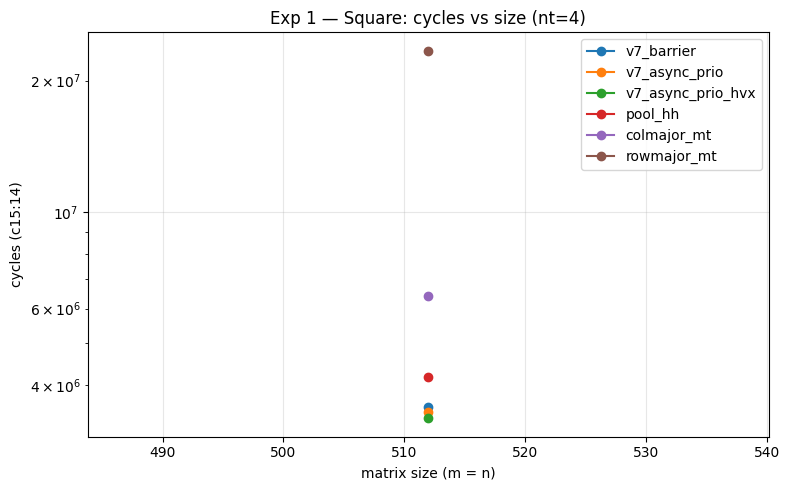

In [6]:

plt.figure(figsize=(8,5))
for v in VARIANTS:
    d = df1[(df1.variant==v) & df1.cycles.notna()].sort_values("m")
    if len(d): plt.plot(d.m, d.cycles, marker="o", label=v)
plt.xlabel("matrix size (m = n)"); plt.ylabel("cycles (c15:14)"); plt.yscale("log")
plt.title("Exp 1 — Square: cycles vs size (nt=4)")
plt.legend(); plt.grid(True, alpha=.3); plt.tight_layout()
plt.savefig(os.path.join(RESULTS,"exp1_square.png"), dpi=120); plt.show()


## Experiment 2 — Tall-skinny size sweep  (n = 64, growing m, nt = 4)
The least-squares regime: per-step reflector cost (∝ m) is a large fraction of
each step, so async_prio's pivot-overlap pays off most here.

In [7]:

EXP2 = [(m, 64, 4) for m in [256, 512, 1024, 2048, 4096]]
print("=== Exp 2: tall-skinny sweep ===", flush=True)
df2 = sweep(EXP2)
df2[["variant","m","n","nt","cycles","status"]]


=== Exp 2: tall-skinny sweep ===
[1/30] v7_barrier 256x64 nt=4 (running; no output until it finishes)...
  v7_barrier     256x64 nt=4 chunk=4: 308322  (183.0s)
[2/30] v7_async_prio 256x64 nt=4 (running; no output until it finishes)...
  v7_async_prio  256x64 nt=4 chunk=4: 279852  (185.8s)
[3/30] v7_async_prio_hvx 256x64 nt=4 (running; no output until it finishes)...
  v7_async_prio_hvx 256x64 nt=4 chunk=4: 275640  (183.2s)
[4/30] pool_hh 256x64 nt=4 (running; no output until it finishes)...
  pool_hh        256x64 nt=4 chunk=4: 349133  (181.2s)
[5/30] colmajor_mt 256x64 nt=4 (running; no output until it finishes)...
  colmajor_mt    256x64 nt=4 chunk=4: 1343013  (314.3s)
[6/30] rowmajor_mt 256x64 nt=4 (running; no output until it finishes)...
  rowmajor_mt    256x64 nt=4 chunk=4: 1036317  (253.6s)
[7/30] v7_barrier 512x64 nt=4 (running; no output until it finishes)...
  v7_barrier     512x64 nt=4 chunk=4: 467718  (220.0s)
[8/30] v7_async_prio 512x64 nt=4 (running; no output until it fi

,variant,m,n,nt,cycles,status
0,v7_barrier,256,64,4,308322,OK
1,v7_async_prio,256,64,4,279852,OK
2,v7_async_prio_hvx,256,64,4,275640,OK
3,pool_hh,256,64,4,349133,OK
4,colmajor_mt,256,64,4,1343013,OK
5,rowmajor_mt,256,64,4,1036317,OK
6,v7_barrier,512,64,4,467718,OK
7,v7_async_prio,512,64,4,397410,OK
8,v7_async_prio_hvx,512,64,4,455106,OK
9,pool_hh,512,64,4,534972,OK


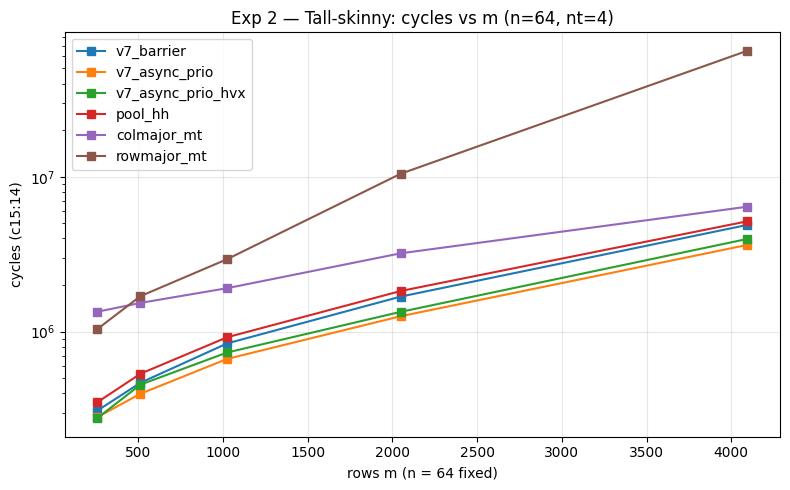

In [8]:

plt.figure(figsize=(8,5))
for v in VARIANTS:
    d = df2[(df2.variant==v) & df2.cycles.notna()].sort_values("m")
    if len(d): plt.plot(d.m, d.cycles, marker="s", label=v)
plt.xlabel("rows m (n = 64 fixed)"); plt.ylabel("cycles (c15:14)"); plt.yscale("log")
plt.title("Exp 2 — Tall-skinny: cycles vs m (n=64, nt=4)")
plt.legend(); plt.grid(True, alpha=.3); plt.tight_layout()
plt.savefig(os.path.join(RESULTS,"exp2_tall.png"), dpi=120); plt.show()


## Experiment 3 — Thread sweep  (nt ∈ {1,2,4,6,8})
Parallel scaling and where the 4-HVX-context limit bites. One square, one tall.

In [ ]:

NTS  = [1, 2, 4, 6, 8]
print("=== Exp 3a: thread sweep, square 256x256 ===", flush=True)
df3a = sweep([(256, 256, nt) for nt in NTS])
print("=== Exp 3b: thread sweep, tall 1024x64 ===", flush=True)
df3b = sweep([(1024, 64, nt) for nt in NTS])
df3  = pd.concat([df3a, df3b], ignore_index=True)
df3[["variant","m","n","nt","cycles","status"]]


=== Exp 3a: thread sweep, square 256x256 ===
[1/30] v7_barrier 256x256 nt=1 (running; no output until it finishes)...
  v7_barrier     256x256 nt=1 chunk=4: 1785252  (333.3s)
[2/30] v7_async_prio 256x256 nt=1 (running; no output until it finishes)...
  v7_async_prio  256x256 nt=1 chunk=4: 1756879  (316.8s)
[3/30] v7_async_prio_hvx 256x256 nt=1 (running; no output until it finishes)...
  v7_async_prio_hvx 256x256 nt=1 chunk=4: 1383953  (312.3s)
[4/30] pool_hh 256x256 nt=1 (running; no output until it finishes)...
  pool_hh        256x256 nt=1 chunk=4: 2618350  (315.2s)
[5/30] colmajor_mt 256x256 nt=1 (running; no output until it finishes)...
  colmajor_mt    256x256 nt=1 chunk=4: 4143012  (211.1s)
[6/30] rowmajor_mt 256x256 nt=1 (running; no output until it finishes)...
  rowmajor_mt    256x256 nt=1 chunk=4: 2510464  (225.3s)
[7/30] v7_barrier 256x256 nt=2 (running; no output until it finishes)...
  v7_barrier     256x256 nt=2 chunk=4: 1065610  (322.5s)
[8/30] v7_async_prio 256x256 nt=2

NameError: name 'df3a' is not defined

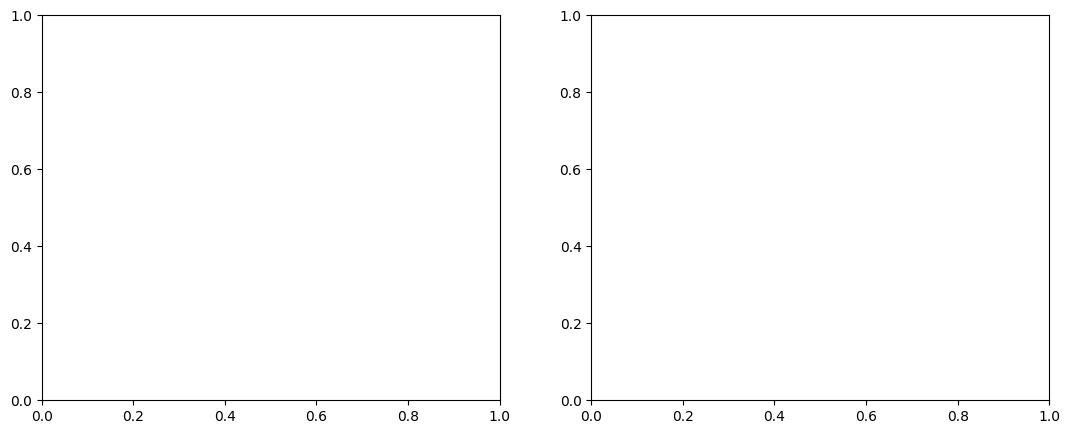

In [3]:

fig, ax = plt.subplots(1, 2, figsize=(13,5))
for a, d, t in [(ax[0], df3a, "square 256x256"), (ax[1], df3b, "tall 1024x64")]:
    for v in VARIANTS:
        s = d[(d.variant==v) & d.cycles.notna()].sort_values("nt")
        if len(s): a.plot(s.nt, s.cycles, marker="o", label=v)
    a.set_xlabel("threads (nt)"); a.set_ylabel("cycles"); a.set_title(f"Exp 3 — {t}")
    a.grid(True, alpha=.3); a.legend()
plt.tight_layout(); plt.savefig(os.path.join(RESULTS,"exp3_threads.png"), dpi=120); plt.show()


## Master table + scheduling-speedup summary
Full CSV (all configs × variants, with every PMU counter) is at
`results_v3/all_runs.csv`. Below: barrier-vs-async_prio speedup, the headline
scheduling metric.

In [ ]:

alldf = pd.read_csv(MASTER)
print("CSV:", MASTER, "| rows:", len(alldf), "| PMU cols:",
      sum(c.startswith("pmu_") for c in alldf.columns))
piv = alldf[alldf.variant.isin(["v7_barrier","v7_async_prio"]) & alldf.cycles.notna()]
piv = piv.pivot_table(index=["m","n","nt"], columns="variant", values="cycles")
if {"v7_barrier","v7_async_prio"} <= set(piv.columns):
    piv["barrier/async_prio"] = (piv["v7_barrier"]/piv["v7_async_prio"]).round(3)
piv
